In [1]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import math
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import sys
import sklearn
import tkinter as tk
from tkinter import filedialog

columns = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal",
    "num"
]

descriptions = {

    "age": "How old are you? Enter your age in years. Example: 45.",

    "sex": "What is your recorded sex? Enter 0 for Female or 1 for Male.",

    "cp": """What type of chest pain do you experience?
    1 = Typical angina (chest discomfort associated with reduced blood supply).
    2 = Atypical angina.
    3 = Non-anginal chest pain.
    4 = Asymptomatic (no chest pain).""",

    "trestbps": "What is your resting systolic blood pressure in mmHg? Example: 120.",

    "chol": "What is your total serum cholesterol level in mg/dL? Example: 200.",

    "fbs": "Is your fasting blood sugar greater than 120 mg/dL? Enter 0 for No or 1 for Yes.",

    "restecg": """What was your resting ECG result?
    0 = Normal.
    1 = ST-T wave abnormality.
    2 = Probable or definite left ventricular hypertrophy.""",

    "thalach": "What was your maximum heart rate during an exercise test? Enter beats per minute. Example: 150.",

    "exang": "Did you experience angina (chest discomfort) during exercise? Enter 0 for No or 1 for Yes.",

    "oldpeak": "What was your exercise-induced ST depression relative to rest? Enter the recorded measurement. Example: 1.5.",

    "slope": """What was the slope of your peak exercise ST segment?
    1 = Upsloping.
    2 = Flat.
    3 = Downsloping.""",

    "ca": "How many major blood vessels were visible by fluoroscopy? Enter 0, 1, 2 or 3.",

    "thal": """What was your thallium stress test result?
    3 = Normal.
    6 = Fixed defect.
    7 = Reversible defect."""
}

valid_values = {
    "sex": [0, 1],
    "cp": [1, 2, 3, 4],
    "fbs": [0, 1],
    "restecg": [0, 1, 2],
    "exang": [0, 1],
    "slope": [1, 2, 3],
    "ca": [0, 1, 2, 3],
    "thal": [3, 6, 7],
    "num": [0, 1, 2, 3, 4]
}
print(df.columns.tolist())
print(user_df.columns.tolist())
print(features)


NameError: name 'df' is not defined

In [53]:
file_path = filedialog.askopenfilename(
    title="Select processed.cleveland.data or a cleaned CSV file",
    filetypes=[
        ("Cleveland dataset", "*.data"),
        ("CSV files", "*.csv"),
        ("All files", "*.*")
    ]
)

# Check file selection
if not file_path:
    print("No file selected.")

else:
    print("Selected:", file_path)

    # Load dataset
    if file_path.lower().endswith(".data"):
        # The original processed.cleveland.data file has no column headers.
        df = pd.read_csv(
            file_path,
            header=None,
            names=columns,
            na_values="?",
            skipinitialspace=True
        )

    else:
        # A cleaned CSV already contains its own column headers.
        df = pd.read_csv(file_path)

        # Keep the Cleveland dataset columns used by this program.
        # This excludes extra metadata columns such as source_file or source_row,
        # if they are present in the cleaned CSV.
        if all(column in df.columns for column in columns):
            df = df[columns]

    # Display dataset
    print("\\nDataset:")
    print(df)

    # Display basic information
    print("\\nDataset dimensions:", df.shape)

    print("\\nColumn data types:")
    print(df.dtypes)

    print("\\nMissing values:")
    print(df.isnull().sum())

    print("\\nFirst five records:")
    print(df.head())
df["heart_disease_present"] = (df["num"] > 0).astype(int) #Mistake

Selected: C:/Users/DELL/Documents/Hackathon/heart_disease_cleveland_clean.csv
\nDataset:
     age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
0     63    1   1       145   233    1        2      150      0      2.3   
1     67    1   4       160   286    0        2      108      1      1.5   
2     67    1   4       120   229    0        2      129      1      2.6   
3     37    1   3       130   250    0        0      187      0      3.5   
4     41    0   2       130   204    0        2      172      0      1.4   
..   ...  ...  ..       ...   ...  ...      ...      ...    ...      ...   
298   45    1   1       110   264    0        0      132      0      1.2   
299   68    1   4       144   193    1        0      141      0      3.4   
300   57    1   4       130   131    0        0      115      1      1.2   
301   57    0   2       130   236    0        2      174      0      0.0   
302   38    1   3       138   175    0        0      173      0      0.0   

FOR MY OWN (HACKATHON's) Dataset
Age
Sex
cp-Chest Pain Type(1-4)
trestbps — Resting blood pressure
chol-serum cholesterol
FBS - Fasting Blood Sugar
restecg — Resting electrocardiographic results (0-2)
thalach — Maximum heart rate achieved
exang — Exercise-induced angina  Angina is a medical condition causing chest pain or discomfort
oldpeak — ST depression The ST segment is the flat, isoelectric portion of an electrocardiogram (ECG) that connects the QRS complex and the T wave
slope — Slope of peak exercise ST segment
ca — Number of major vessels
thal — Thalassemia test result
num — Heart disease diagnosis  My variable to assess patients condition  (0-4 depending on severity)


In [54]:

user_data = {}

for column in df.columns:

    if column not in ["num", "heart_disease_present"]:

        print("\n" + "=" * 50)
        print(column.upper())
        print(descriptions[column]) # Outside the llop to prevent continuous repetition of the description

        while True: #Indefinite loop to keep asking for input until valid data is provided
            try:
                UserData = input("\nEnter your answer: ") #Vague data type to accept any input from the user

                # Check for empty input
                if UserData == "": #Presence check
                    print("Input cannot be empty. Try again.")
                    continue

                # Validate specific columns
                if column in valid_values:

                    if not UserData.isdigit(): # Type check to ensure the input is a number
                        print("This input is not a number. Please enter a number.")
                        continue

                    if int(UserData) not in valid_values[column]: #Lookup check to ensure the input is within the valid range
                        print(f"Invalid input. Please enter one of the following values: {valid_values[column]}")
                        continue

                # Reached only if all checks pass
                break

            except KeyboardInterrupt:
                print("\nInput interrupted.")
                raise

        user_data[column] = UserData
# Continue immediately skips the rest of the code
print(user_data)


AGE
How old are you? Enter your age in years. Example: 45.

SEX
What is your recorded sex? Enter 0 for Female or 1 for Male.

CP
What type of chest pain do you experience?
    1 = Typical angina (chest discomfort associated with reduced blood supply).
    2 = Atypical angina.
    3 = Non-anginal chest pain.
    4 = Asymptomatic (no chest pain).

TRESTBPS
What is your resting systolic blood pressure in mmHg? Example: 120.

CHOL
What is your total serum cholesterol level in mg/dL? Example: 200.

FBS
Is your fasting blood sugar greater than 120 mg/dL? Enter 0 for No or 1 for Yes.

RESTECG
What was your resting ECG result?
    0 = Normal.
    1 = ST-T wave abnormality.
    2 = Probable or definite left ventricular hypertrophy.

THALACH
What was your maximum heart rate during an exercise test? Enter beats per minute. Example: 150.

EXANG
Did you experience angina (chest discomfort) during exercise? Enter 0 for No or 1 for Yes.

OLDPEAK
What was your exercise-induced ST depression relative 

In [55]:
#Conversion of Data
user_data["age"] = int(user_data["age"])
user_data["sex"] = int(user_data["sex"])
user_data["oldpeak"] = float(user_data["oldpeak"])
user_df = pd.DataFrame([user_data]) #Creates a data fram to append to df

In [56]:
features = [
    column for column in df.columns
    if column not in ["num", "heart_disease_present"]
]

user_df = user_df[features]

for column in user_df.columns:
    user_df[column] = user_df[column].astype(df[column].dtype)

combined_df = pd.concat([df, user_df], ignore_index=True)
print(f"Original DataFrame {df}")
for column in columns: 
    if column != "num":   
        print(f"Column: {column}, User Data: {user_data[column]}")
print(f"Combined DataFrame {combined_df}")


Original DataFrame      age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
0     63    1   1       145   233    1        2      150      0      2.3   
1     67    1   4       160   286    0        2      108      1      1.5   
2     67    1   4       120   229    0        2      129      1      2.6   
3     37    1   3       130   250    0        0      187      0      3.5   
4     41    0   2       130   204    0        2      172      0      1.4   
..   ...  ...  ..       ...   ...  ...      ...      ...    ...      ...   
298   45    1   1       110   264    0        0      132      0      1.2   
299   68    1   4       144   193    1        0      141      0      3.4   
300   57    1   4       130   131    0        0      115      1      1.2   
301   57    0   2       130   236    0        2      174      0      0.0   
302   38    1   3       138   175    0        0      173      0      0.0   

     slope   ca  thal  num  heart_disease_present  
0        3  0.0 

In [57]:
def AgeDisplay():
    print("Age statistics:")
    print(df["age"].describe())

    age_comparison = df.groupby(df["num"] > 0)["age"].agg(
        ["count", "mean", "median", "min", "max"]
    )
    print(age_comparison)

# AGE DISTRIBUTION GRAPH

    plt.figure(figsize=(10, 6))

    for label, name in [(False, "No disease"), (True, "Disease present")]:

        ages = df[df["num"] > 0 if label else df["num"] == 0]["age"]

        plt.hist(ages, bins=12, edgecolor='black', alpha=0.6, label=name)

    plt.title("Age Distribution by Heart Disease Classification")
    plt.xlabel("Age (years)")
    plt.ylabel("Number of patients")
    plt.legend()
    plt.show()


def SexDisplay():
    # Count patients by sex and diagnosis
    male = df[df["sex"] == 1]["num"].value_counts().sort_index()
    female = df[df["sex"] == 0]["num"].value_counts().sort_index()
    

    # Define positions
    x = np.arange(5)
    width = 0.35

    # Plot bars
    plt.bar(x - width/2, male.reindex(range(5), fill_value=0),
            width, label="Male")

    plt.bar(x + width/2, female.reindex(range(5), fill_value=0), #If ur data isn't indexed every 5 rows fill gaps with 0
            width, label="Female")

    # Define labels
    plt.xticks(x, ["No disease", "Level 1", "Level 2", "Level 3", "Level 4"]) # places ticks at the center of the bars and labels them with the diagnosis levels

    plt.title("Heart Disease Diagnosis by Sex")
    plt.xlabel("Diagnosis")
    plt.ylabel("Number of Patients")

    plt.legend(title="Sex")
    plt.grid(axis="y", alpha=0.3)

    plt.show()

def CPDisplay():

    # Separate patients by chest pain type and diagnosis
    no_disease = df[df["num"] == 0]["cp"].value_counts().sort_index()

    disease = df[df["num"] > 0]["cp"].value_counts().sort_index()

    # Define positions
    x = np.arange(4)
    width = 0.35

    # Plot bars
    plt.bar(x - width/2, no_disease.reindex(range(4), fill_value=0),
            width, label="No Disease")

    plt.bar(x + width/2, disease.reindex(range(4), fill_value=0),
            width, label="Heart Disease")

    # Define chest pain labels
    plt.xticks(x, [
        "Typical Angina",
        "Atypical Angina",
        "Non-anginal Pain",
        "Asymptomatic"
    ])

    plt.title("Chest Pain Type vs Heart Disease")
    plt.xlabel("Chest Pain Type")
    plt.ylabel("Number of Patients")

    plt.legend(title="Diagnosis")
    plt.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

def TrestbpsDisplay():

    plt.hist(df["trestbps"], bins=15, edgecolor="black")

    plt.title("Distribution of Resting Blood Pressure")
    plt.xlabel("Resting Blood Pressure (mmHg)")
    plt.ylabel("Number of Patients")

    plt.grid(axis="y", alpha=0.3)
    plt.show()


def CholDisplay():


    plt.hist(df["chol"], bins=15, edgecolor="black")

    plt.title("Distribution of Serum Cholesterol")
    plt.xlabel("Cholesterol (mg/dl)")
    plt.ylabel("Number of Patients")

    plt.grid(axis="y", alpha=0.3)
    plt.show()

def FbsDisplay():

    fbs = df["fbs"].value_counts().sort_index() # Counts occurrences and sorts the index to ensure 0 and 1 are in order

    plt.bar(["Below/Equal 120", "Above 120"], 
            fbs.reindex([0, 1], fill_value=0))

    plt.title("Fasting Blood Sugar Distribution")
    plt.xlabel("Fasting Blood Sugar")
    plt.ylabel("Number of Patients")

    plt.grid(axis="y", alpha=0.3)
    plt.show()

def RestecgDisplay():

    restecg = df["restecg"].value_counts().sort_index()

    plt.bar(["Normal", "ST-T Abnormality", "LV Hypertrophy"],
            restecg.reindex([0, 1, 2], fill_value=0))

    plt.title("Resting ECG Results")
    plt.xlabel("ECG Category")
    plt.ylabel("Number of Patients")

    plt.grid(axis="y", alpha=0.3)
    plt.show()

def ThalachDisplay():

    plt.hist(df["thalach"], bins=15, edgecolor="black")

    plt.title("Distribution of Maximum Heart Rate")
    plt.xlabel("Maximum Heart Rate (bpm)")
    plt.ylabel("Number of Patients")

    plt.grid(axis="y", alpha=0.3)
    plt.show()

def ExangDisplay():

    exang = df["exang"].value_counts().sort_index()

    plt.bar(["No", "Yes"], exang.reindex([0, 1], fill_value=0))

    plt.title("Exercise-Induced Angina")
    plt.xlabel("Angina")
    plt.ylabel("Number of Patients")

    plt.grid(axis="y", alpha=0.3)
    plt.show()

def OldpeakDisplay():

    plt.hist(df["oldpeak"], bins=15, edgecolor="black")

    plt.title("Distribution of ST Depression")
    plt.xlabel("Oldpeak")
    plt.ylabel("Number of Patients")

    plt.grid(axis="y", alpha=0.3)
    plt.show()

def SlopeDisplay():

    slope = df["slope"].value_counts().sort_index()

    plt.bar(["Upsloping", "Flat", "Downsloping"],
            slope.reindex([1, 2, 3], fill_value=0))

    plt.title("Slope of Peak Exercise ST Segment")
    plt.xlabel("Slope Category")
    plt.ylabel("Number of Patients")

    plt.grid(axis="y", alpha=0.3)
    plt.show()

def CaDisplay():

    ca = df["ca"].value_counts().sort_index()

    plt.bar(ca.index.astype(str), ca.values)

    plt.title("Number of Major Vessels")
    plt.xlabel("Number of Vessels")
    plt.ylabel("Number of Patients")

    plt.grid(axis="y", alpha=0.3)
    plt.show()

def ThalDisplay():

    thal = df["thal"].value_counts().sort_index()

    plt.bar(thal.index.astype(str), thal.values)

    plt.title("Thalassemia Distribution")
    plt.xlabel("Thalassemia Category")
    plt.ylabel("Number of Patients")

    plt.grid(axis="y", alpha=0.3)
    plt.show()






['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']
Age statistics:
count    303.000000
mean      54.438944
std        9.038662
min       29.000000
25%       48.000000
50%       56.000000
75%       61.000000
max       77.000000
Name: age, dtype: float64
       count       mean  median  min  max
num                                      
False    164  52.585366    52.0   29   76
True     139  56.625899    58.0   35   77


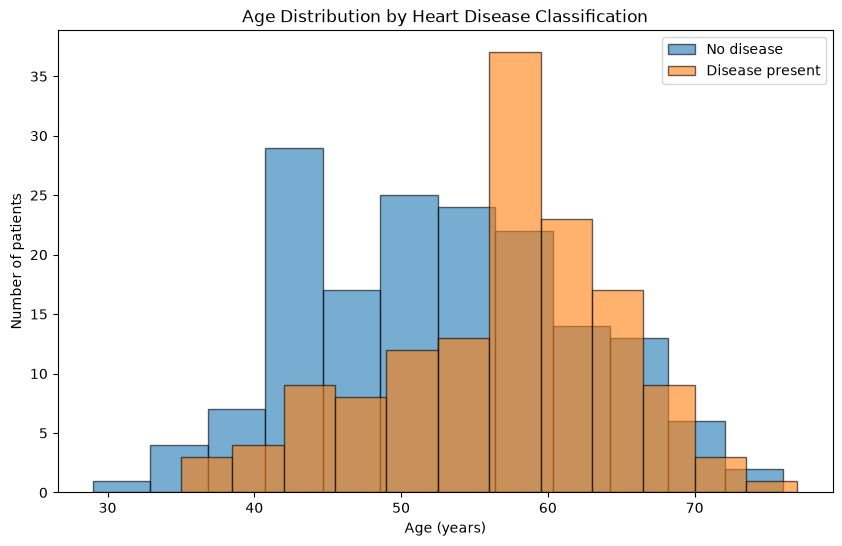

In [ ]:
print(columns)

Userchoice = input("What would you like to display? ")

try:
    while Userchoice != "":

        if Userchoice.lower() == "age":
            AgeDisplay()

        elif Userchoice.lower() == "sex":
            SexDisplay()

        elif Userchoice.lower() == "cp":
            CPDisplay()

        elif Userchoice.lower() == "trestbps":
            TrestbpsDisplay()

        elif Userchoice.lower() == "chol":
            CholDisplay()

        elif Userchoice.lower() == "fbs":
            FbsDisplay()

        elif Userchoice.lower() == "restecg":
            RestecgDisplay()

        elif Userchoice.lower() == "thalach":
            ThalachDisplay()

        elif Userchoice.lower() == "exang":
            ExangDisplay()

        elif Userchoice.lower() == "oldpeak":
            OldpeakDisplay()

        elif Userchoice.lower() == "slope":
            SlopeDisplay()

        elif Userchoice.lower() == "ca":
            CaDisplay()

        elif Userchoice.lower() == "thal":
            ThalDisplay()

        else:
            print("Invalid column name.")

        Userchoice = input("\nWhat else would you like to display? ")

except KeyboardInterrupt:
    print("\nInput interrupted.")
    raise

Let's understand every parameter.
Parameter	Purpose
X	Features
y	Target
test_size=0.2	20% reserved for testing
random_state=42	Makes the split reproducible
stratify=y	Maintains class proportions in both sets


The function returns four datasets:
- X_train: Training features.
- X_test: Testing features.
- y_train: Training answers.
- y_test: Testing answers.
Important: The model learns from X_train and y_train. It is evaluated against X_test and y_test.

In [ ]:
# It's time for machine learning!
X = df.drop(columns=["num", "heart_disease_present"])
y = df["heart_disease_present"]

print("Features:", X.shape)
print("Target:", y.shape)

# Separating training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X_test_original = X_test.copy()
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

#Create and train the model
imputer = SimpleImputer(strategy="most_frequent")

X_train = imputer.fit_transform(X_train) # I used fit_transform on the training data to learn the imputation strategy and apply it to the training set.

X_test = imputer.transform(X_test)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

# Make predictions
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

probabilities = model.predict_proba(X_test)


user_df = pd.DataFrame([user_data])

# Ensure features are in the correct order
user_df = user_df[X.columns]

# Apply the same imputation and scaling
user_df = imputer.transform(user_df)
user_df = scaler.transform(user_df)

# Calculate probability
probability = model.predict_proba(user_df)[0][1]

print(f"Estimated probability: {probability * 100:.2f}%")

Features: (303, 13)
Target: (303,)
Estimated probability: 58.27%


In [ ]:
results = pd.DataFrame({
    "Actual": y_test.map({
        0: "No heart disease",
        1: "Heart disease"
    }),

    "Predicted": [
        "Heart disease" if prediction == 1 else "No heart disease"
        for prediction in predictions
    ]
})

print(results.to_string(index=False))
cm = confusion_matrix(y_test, predictions)

print(cm)
print(classification_report(y_test, predictions))

accuracy = accuracy_score(y_test, predictions)

print(f"Model Accuracy: {accuracy:.2%}")

print("=" * 45)
print("HEART DISEASE MODEL ESTIMATE")
print("=" * 45)

print(f"Estimated probability if you have heart disease: {probability * 100:.2f}%")

print("=" * 45)


# Create the baseline model
baseline = DummyClassifier(strategy="most_frequent")

# Train the baseline
baseline.fit(X_train, y_train)

# Make baseline predictions
baseline_predictions = baseline.predict(X_test)

# Calculate scores
baseline_accuracy = accuracy_score(y_test, baseline_predictions)

model_accuracy = accuracy_score(y_test, predictions)

# Compare
print("MODEL COMPARISON")
print("=" * 40)

print(f"Baseline accuracy: {baseline_accuracy:.2%}")
print(f"Logistic Regression accuracy: {model_accuracy:.2%}")

print("=" * 40)

print(f"Improvement: {(model_accuracy - baseline_accuracy) * 100:.2f} percentage points")

          Actual        Predicted
No heart disease No heart disease
No heart disease    Heart disease
No heart disease No heart disease
No heart disease No heart disease
No heart disease    Heart disease
No heart disease No heart disease
No heart disease No heart disease
No heart disease No heart disease
   Heart disease    Heart disease
No heart disease No heart disease
   Heart disease    Heart disease
No heart disease No heart disease
No heart disease No heart disease
   Heart disease    Heart disease
   Heart disease    Heart disease
   Heart disease    Heart disease
   Heart disease    Heart disease
No heart disease No heart disease
   Heart disease    Heart disease
   Heart disease    Heart disease
No heart disease    Heart disease
No heart disease No heart disease
   Heart disease    Heart disease
No heart disease    Heart disease
   Heart disease    Heart disease
No heart disease No heart disease
No heart disease No heart disease
   Heart disease    Heart disease
No heart disea